# Complete RF + PyTorch hybrid for building-age classification

This notebook contains **all model training, evaluation, export, reload and prediction code**, without importing project training scripts or relying on saved model predictions.

The evaluated hybrid is:

```text
P(hybrid) = 0.25 × P(Madrid RF)
          + 0.25 × P(Amsterdam RF)
          + 0.50 × P(Madrid-pretrained, Amsterdam-fine-tuned MLP)
```

Its observed development macro F1 is **0.5679**, versus **0.5494** for the original RF blend, on five spatial folds and three matched 25/class samples. These are previously used development folds, not an independent competition test. The severe-error rate rose from 8.63% to 9.53%.

**Run order:** execute every cell from top to bottom. The notebook retrains both Madrid models, performs all 15 Amsterdam evaluations, then trains and exports a separate final model using only 100 Amsterdam adaptation labels. Expect a few minutes on CPU.

**Prerequisites:** run `notebooks/workflow/preprocessing_age_labels.ipynb` first. This notebook starts from the resulting feature tables, folds and sample memberships; it does not repeat raw Parquet preprocessing.

From the repository root, prepare and launch the environment:

```bash
uv sync --locked --extra deep-learning
uv run --extra deep-learning --with jupyter jupyter lab
```

Python packages used: PyTorch, scikit-learn, pandas, NumPy, PyArrow, Matplotlib and joblib. Outputs go only to `data/hybrid_rf_pytorch/`.

## 1. Imports, paths and fixed settings

In [1]:
from copy import deepcopy
from pathlib import Path
import hashlib
import json
import os
import platform
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

ROOT_OVERRIDE = None  # Set to Path('/path/to/Building_Age_Classification') if needed.
ROOT = Path(ROOT_OVERRIDE).resolve() if ROOT_OVERRIDE is not None else next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / 'pyproject.toml').is_file() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the repository or set ROOT_OVERRIDE.')
os.chdir(ROOT)
INPUT = ROOT / 'data/preprocessed_age_labels'
OUT = ROOT / 'data/hybrid_rf_pytorch'
OUT.mkdir(parents=True, exist_ok=True)
CLASSES = np.arange(1, 5)
CONFIG = dict(seed=42, hidden=[64, 32], dropout=0.2,
              target_boundaries=[1945, 1984, 2004, 2024],
              source_checkpoint_fold=0, source_max_epochs=80, source_patience=12,
              source_batch_size=512, source_learning_rate=0.001,
              target_epochs=300, head_learning_rate=0.001,
              encoder_learning_rate=0.0001, weight_decay=0.01,
              folds=5, repetitions=3, labels_per_class=25,
              rf_blend_weight=0.5, device='cpu')
RF_PARAMETERS = dict(n_estimators=150, max_features='sqrt', min_samples_leaf=2,
                     class_weight='balanced_subsample', n_jobs=min(4, os.cpu_count() or 1))
METRICS = ['macro_f1', 'weighted_f1', 'accuracy', 'balanced_accuracy', 'severe_error_rate']
torch.set_num_threads(2)
STARTED = time.monotonic()
print('Repository:', ROOT)
print('PyTorch:', torch.__version__, '| scikit-learn:', sklearn.__version__)
print('Device: CPU; deterministic algorithms; fixed settings, no outer-fold tuning.')

Repository: /home/mirado/hack4dev/Building_Age_Classification
PyTorch: 2.15.0+cpu | scikit-learn: 1.9.1
Device: CPU; deterministic algorithms; fixed settings, no outer-fold tuning.


## 2. Read data and preserve the feature allowlist

The 54 predictors are nine summaries per spectral band. IDs and coordinates are used only for matching and spatial exclusion. Construction years are used only to construct source labels.

Madrid RF retains the original Madrid labels (first boundary 1960), matching the evaluated RF baseline. The neural source task uses Amsterdam boundaries (first boundary 1945).

In [2]:
REQUIRED = [INPUT / name for name in [
    'configuration.json', 'madrid_supervised_features.parquet',
    'amsterdam_supervised_features.parquet', 'amsterdam_few_shot_membership.csv']]
missing = [str(p) for p in REQUIRED if not p.exists()]
if missing:
    raise FileNotFoundError('Run preprocessing_age_labels.ipynb first. Missing: ' + ', '.join(missing))
preprocessing_config = json.loads(REQUIRED[0].read_text())
FEATURES = preprocessing_config['default_feature_names']
assert len(FEATURES) == 54 and preprocessing_config['n_folds'] == 5
assert not set(FEATURES).intersection(
    {'weighted_mean_year', 'age_class', 'location_id', 'city', 'px_key', 'py_key', 'fold'})
madrid = pd.read_parquet(REQUIRED[1]).reset_index(drop=True)
amsterdam = pd.read_parquet(REQUIRED[2]).reset_index(drop=True)
saved_memberships = pd.read_csv(REQUIRED[3]).rename(columns={'validation_fold': 'fold'})
# Preprocessing stores repetition 0 only. Regenerate the baseline's three exact
# repetitions with its SeedSequence algorithm, and verify repetition 0.
membership_parts = []
for fold in range(CONFIG['folds']):
    eligible = amsterdam.loc[amsterdam.fold.ne(fold)]
    for repetition in range(CONFIG['repetitions']):
        rng = np.random.default_rng(np.random.SeedSequence([CONFIG['seed'], repetition, fold]))
        selected = []
        for cls in CLASSES:
            candidates = eligible.loc[eligible.age_class.eq(cls), 'location_id'].sort_values().to_numpy()
            selected.extend(rng.permutation(candidates)[:25])
        part = amsterdam.set_index('location_id', drop=False).loc[selected, ['location_id', 'age_class']].copy()
        part['fold'], part['repetition'], part['samples_per_class'] = fold, repetition, 25
        membership_parts.append(part.reset_index(drop=True))
        if repetition == 0:
            saved_ids = saved_memberships.loc[saved_memberships.fold.eq(fold)
                & saved_memberships.samples_per_class.eq(25), 'location_id']
            assert set(selected) == set(saved_ids)
memberships = pd.concat(membership_parts, ignore_index=True)
for name, table in [('Madrid', madrid), ('Amsterdam', amsterdam)]:
    assert table.location_id.is_unique
    assert set(table.age_class) == set(CLASSES)
    assert table.groupby('spatial_group').fold.nunique().eq(1).all()
    assert not np.isinf(table[FEATURES].to_numpy()).any()
    print(name, len(table), 'locations; counts:', table.age_class.value_counts().sort_index().to_dict())
assert set(madrid.location_id).isdisjoint(amsterdam.location_id)
assert len(memberships) == 5 * 3 * 100
assert memberships.groupby(['fold', 'repetition']).location_id.nunique().eq(100).all()
display(pd.DataFrame({'position': np.arange(54), 'feature': FEATURES}).head(12))

Madrid 76263 locations; counts: {1: 13794, 2: 27152, 3: 18672, 4: 16645}
Amsterdam 25992 locations; counts: {1: 7568, 2: 8802, 3: 6745, 4: 2877}


,position,feature
0,0,Blue_mean
1,1,Blue_std
2,2,Blue_median
3,3,Blue_min
4,4,Blue_max
5,5,Blue_early_mean
6,6,Blue_late_mean
7,7,Blue_late_minus_early
8,8,Blue_slope_per_year
9,9,Green_mean


## 3. Model and scoring functions

In [3]:
def sha(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def seed_all(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)

def score(y, p):
    pred = CLASSES[p.argmax(axis=1)]
    return dict(macro_f1=f1_score(y, pred, labels=CLASSES, average='macro', zero_division=0),
                weighted_f1=f1_score(y, pred, labels=CLASSES, average='weighted', zero_division=0),
                accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred))

class TransferMLP(nn.Module):
    def __init__(self, n_features=54):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(CONFIG['dropout']),
                                     nn.Linear(64, 32), nn.ReLU(), nn.Dropout(CONFIG['dropout']))
        self.head = nn.Linear(32, 4)

    def forward(self, x):
        return self.head(self.encoder(x))

def metrics(y, p):
    return dict(**score(y, p), severe_error_rate=float(np.mean(np.abs(y - CLASSES[p.argmax(1)]) >= 2)))

def probabilities(model, x):
    model.eval()
    with torch.inference_mode():
        return torch.cat([model(batch).softmax(1) for batch in x.split(2048)]).numpy()

def source_labels(source):
    # Only the supervised target vector uses construction year; never a predictor.
    years = source.weighted_mean_year.to_numpy()
    assert np.isfinite(years).all() and (years >= 1850).all() and (years <= 2024).all()
    labels = np.searchsorted(CONFIG['target_boundaries'], years, side='left') + 1
    assert set(labels) == set(CLASSES)
    return labels

In [4]:
def make_forest(seed):
    return make_pipeline(
        SimpleImputer(strategy='median', keep_empty_features=True),
        RandomForestClassifier(random_state=seed, **RF_PARAMETERS))


def forest_probabilities(model, frame):
    assert set(model.classes_) == set(CLASSES)
    p = model.predict_proba(frame[FEATURES])
    p = p[:, [list(model.classes_).index(c) for c in CLASSES]]
    validate_probabilities(p, len(frame))
    return p


def validate_probabilities(p, n):
    assert p.shape == (n, 4) and np.isfinite(p).all() and (p >= 0).all()
    np.testing.assert_allclose(p.sum(axis=1), 1, atol=1e-6)


def hybrid_probabilities(source_rf, target_rf, neural, preprocessing, frame):
    if frame.empty:
        raise ValueError('Provide at least one feature row.')
    missing = set(FEATURES).difference(frame.columns)
    if missing:
        raise ValueError(f'Missing predictors: {sorted(missing)}')
    if np.isinf(frame[FEATURES].to_numpy(dtype=float)).any():
        raise ValueError('Predictors contain infinity; fix feature preparation first.')
    p_source = forest_probabilities(source_rf, frame)
    p_target = forest_probabilities(target_rf, frame)
    x = torch.tensor(preprocessing.transform(frame[FEATURES]), dtype=torch.float32)
    p_neural = probabilities(neural, x)
    p_rf = 0.5 * p_source + 0.5 * p_target
    p = 0.5 * p_rf + 0.5 * p_neural
    validate_probabilities(p, len(frame))
    return p

## 4. Pretrain the neural network on Madrid

Only Madrid folds 1–4 fit the imputer, scaler and network. Madrid fold 0 selects the checkpoint by macro F1. AdamW uses class-weighted cross entropy and dropout. Early stopping never sees Amsterdam features or labels.

The selected source model is shared across all Amsterdam folds. This reproduces the original transfer experiment and does not estimate variability from multiple Madrid training seeds.

In [5]:
def pretrain(source, features):
    seed_all(CONFIG['seed'])
    labels = source_labels(source)
    fit = source.fold.ne(CONFIG['source_checkpoint_fold']).to_numpy()
    check = ~fit
    assert set(source.loc[fit, 'spatial_group']).isdisjoint(source.loc[check, 'spatial_group'])
    preprocessing = make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler())
    train_x = torch.tensor(preprocessing.fit_transform(source.loc[fit, features]), dtype=torch.float32)
    check_x = torch.tensor(preprocessing.transform(source.loc[check, features]), dtype=torch.float32)
    train_y = torch.tensor(labels[fit] - 1, dtype=torch.long)
    weights = len(train_y) / (4 * torch.bincount(train_y).float())
    model = TransferMLP(len(features))
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['source_learning_rate'], weight_decay=CONFIG['weight_decay'])
    best_f1, best_epoch, stale, history = -np.inf, 0, 0, []
    for epoch in range(CONFIG['source_max_epochs']):
        model.train()
        total = 0
        for idx in torch.randperm(len(train_x)).split(CONFIG['source_batch_size']):
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(train_x[idx]), train_y[idx], weight=weights)
            assert torch.isfinite(loss)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        p = probabilities(model, check_x)
        checkpoint_f1 = f1_score(labels[check], CLASSES[p.argmax(1)], labels=CLASSES, average='macro', zero_division=0)
        history.append(dict(epoch=epoch+1, training_loss=total/len(train_x), checkpoint_macro_f1=checkpoint_f1))
        if checkpoint_f1 > best_f1 + 1e-5:
            best_f1, best_epoch, stale = checkpoint_f1, epoch+1, 0
            best_state = deepcopy(model.state_dict())
        else:
            stale += 1
        if (epoch+1) % 10 == 0:
            print(f'Madrid epoch {epoch+1}: checkpoint F1 {checkpoint_f1:.4f}', flush=True)
        if stale >= CONFIG['source_patience']:
            break
    model.load_state_dict(best_state)
    model.eval()
    pd.DataFrame(history).to_csv(OUT / 'source_history.csv', index=False)
    source[['location_id', 'spatial_group', 'fold']].assign(
        pretraining_partition=np.where(fit, 'fit', 'checkpoint'),
        original_age_class=source.age_class.to_numpy(),
        harmonized_age_class=labels).to_parquet(OUT / 'source_membership.parquet', index=False)
    joblib.dump(preprocessing, OUT / 'source_preprocessor.joblib')
    torch.save(dict(state_dict=model.state_dict(), config=CONFIG, features=features), OUT / 'source_weights.pt')
    details = dict(n_fit=int(fit.sum()), n_checkpoint=int(check.sum()),
                   best_epoch=best_epoch, checkpoint_macro_f1=best_f1,
                   relabeled_locations=int(np.sum(labels != source.age_class.to_numpy())),
                   fit_class_counts=np.bincount(labels[fit], minlength=5)[1:].tolist(),
                   checkpoint_class_counts=np.bincount(labels[check], minlength=5)[1:].tolist())
    print(f'Madrid pretraining complete: {details}', flush=True)
    return model, preprocessing, details

Madrid epoch 10: checkpoint F1 0.5799


Madrid epoch 20: checkpoint F1 0.5837


Madrid epoch 30: checkpoint F1 0.5904


Madrid epoch 40: checkpoint F1 0.5935


Madrid epoch 50: checkpoint F1 0.5932


Madrid epoch 60: checkpoint F1 0.5991


Madrid pretraining complete: {'n_fit': 61010, 'n_checkpoint': 15253, 'best_epoch': 52, 'checkpoint_macro_f1': 0.6027853350831158, 'relabeled_locations': 8450, 'fit_class_counts': [4310, 28447, 14937, 13316], 'checkpoint_class_counts': [1034, 7155, 3735, 3329]}


n_fit                                            61010
n_checkpoint                                     15253
best_epoch                                          52
checkpoint_macro_f1                           0.602785
relabeled_locations                               8450
fit_class_counts           [4310, 28447, 14937, 13316]
checkpoint_class_counts       [1034, 7155, 3735, 3329]
dtype: object

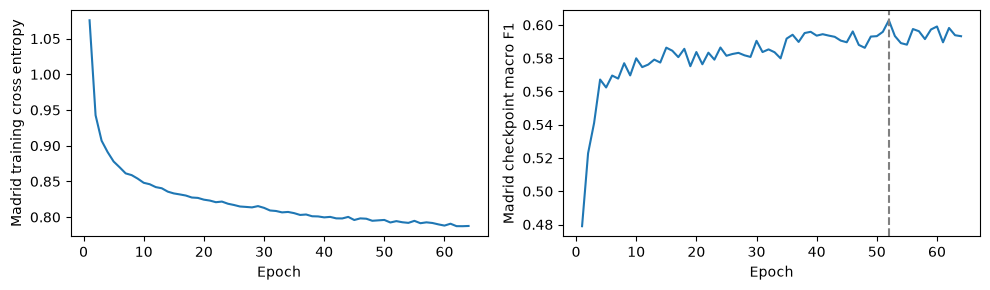

In [6]:
source_neural, neural_preprocessing, source_details = pretrain(madrid, FEATURES)
display(pd.Series(source_details))
source_history = pd.read_csv(OUT / 'source_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(source_history.epoch, source_history.training_loss)
axes[0].set(xlabel='Epoch', ylabel='Madrid training cross entropy')
axes[1].plot(source_history.epoch, source_history.checkpoint_macro_f1)
axes[1].axvline(source_details['best_epoch'], color='gray', linestyle='--')
axes[1].set(xlabel='Epoch', ylabel='Madrid checkpoint macro F1')
fig.tight_layout()
plt.show()

## 5. Train Madrid RF

Fit on all Madrid supervised locations with the original city-specific labels, exactly as in the RF baseline. Its imputer fits only Madrid. Nothing is fitted on Amsterdam evaluation data.

In [7]:
source_rf = make_forest(CONFIG['seed'])
source_rf.fit(madrid[FEATURES], madrid.age_class)
joblib.dump(source_rf, OUT / 'madrid_rf.joblib', compress=3)
source_rf_target_p = forest_probabilities(source_rf, amsterdam)
print('Madrid RF fitted on', len(madrid), 'locations.')

Madrid RF fitted on 76263 locations.


## 6. Fine-tuning and exact adaptation samples

Only the pretrained encoder weights are transferred; the Amsterdam classifier head starts fresh. Both layers of the encoder train at learning rate 0.0001 and the head at 0.001 for 300 fixed full-batch epochs. No outer evaluation label chooses the training duration.

The saved preprocessing membership table provides the same ordered 25/class samples used in the previous experiments. Both Amsterdam RF and neural fine-tuning use that exact sample.

In [8]:
def fine_tune(source_model, x, y, seed):
    seed_all(seed)
    model = TransferMLP(x.shape[1])
    model.encoder.load_state_dict(source_model.encoder.state_dict())
    optimizer = torch.optim.AdamW([
        {'params': model.encoder.parameters(), 'lr': CONFIG['encoder_learning_rate']},
        {'params': model.head.parameters(), 'lr': CONFIG['head_learning_rate']}],
        weight_decay=CONFIG['weight_decay'])
    history = []
    for epoch in range(CONFIG['target_epochs']):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(model(x), y)
        assert torch.isfinite(loss)
        loss.backward()
        optimizer.step()
        history.append(dict(epoch=epoch+1, training_loss=loss.item()))
    model.eval()
    return model, history


def adaptation_sample(fold, repetition):
    ids = memberships.loc[memberships.fold.eq(fold) & memberships.repetition.eq(repetition), 'location_id']
    assert ids.is_unique and len(ids) == 100
    sample = amsterdam.set_index('location_id', drop=False).loc[ids].reset_index(drop=True)
    valid = amsterdam.loc[amsterdam.fold.eq(fold)]
    assert sample.age_class.value_counts().reindex(CLASSES).eq(25).all()
    assert set(sample.location_id).isdisjoint(valid.location_id)
    assert set(sample.spatial_group).isdisjoint(valid.spatial_group)
    return sample

## 7. Run all 15 matched spatial evaluations

The original RF is a 50/50 Madrid/Amsterdam RF blend. The final hybrid then averages that RF blend and the fine-tuned network. All three methods below are evaluated on identical locations. Predictions, probabilities, label memberships, per-class metrics and loss curves are saved.

In [9]:
run_rows, prediction_parts, class_rows, loss_rows, audit_rows = [], [], [], [], []
example_models = None
for fold in range(CONFIG['folds']):
    mask = amsterdam.fold.eq(fold).to_numpy()
    valid = amsterdam.loc[mask]
    y = valid.age_class.to_numpy(dtype=int)
    valid_x = torch.tensor(neural_preprocessing.transform(valid[FEATURES]), dtype=torch.float32)
    for repetition in range(CONFIG['repetitions']):
        seed = 10042 + 100 * fold + repetition
        sample = adaptation_sample(fold, repetition)
        target_rf = make_forest(seed)
        target_rf.fit(sample[FEATURES], sample.age_class)
        train_x = torch.tensor(neural_preprocessing.transform(sample[FEATURES]), dtype=torch.float32)
        train_y = torch.tensor(sample.age_class.to_numpy(dtype=np.int64) - 1)
        target_neural, history = fine_tune(source_neural, train_x, train_y, seed)
        p_target_rf = forest_probabilities(target_rf, valid)
        p_rf = 0.5 * source_rf_target_p[mask] + 0.5 * p_target_rf
        p_neural = probabilities(target_neural, valid_x)
        p_hybrid = 0.5 * p_rf + 0.5 * p_neural
        candidates = {'original_blend': p_rf, 'fine_tuned': p_neural, 'hybrid': p_hybrid}
        for method, p in candidates.items():
            validate_probabilities(p, len(valid))
            pred = CLASSES[p.argmax(axis=1)]
            run_rows.append(dict(method=method, fold=fold, repetition=repetition, **metrics(y, p)))
            prediction_parts.append(pd.DataFrame(dict(
                location_id=valid.location_id.to_numpy(), spatial_group=valid.spatial_group.to_numpy(),
                y_true=y, y_pred=pred, method=method, fold=fold, repetition=repetition,
                **{f'p{c}': p[:, i] for i, c in enumerate(CLASSES)})))
            precision, recall, f1, support = precision_recall_fscore_support(y, pred, labels=CLASSES, zero_division=0)
            class_rows.extend(dict(method=method, fold=fold, repetition=repetition, age_class=int(c),
                                   precision=precision[i], recall=recall[i], f1=f1[i], support=int(support[i]))
                              for i, c in enumerate(CLASSES))
        loss_rows.extend(dict(fold=fold, repetition=repetition, **h) for h in history)
        audit_rows.append(dict(fold=fold, repetition=repetition, target_labels=100,
                               overlap_locations=0, overlap_spatial_groups=0))
        if fold == 0 and repetition == 0:
            example_models = (deepcopy(target_rf), deepcopy(target_neural))
    print(f'Completed Amsterdam fold {fold+1}/5; total elapsed {time.monotonic()-STARTED:.1f}s', flush=True)
runs = pd.DataFrame(run_rows)
predictions = pd.concat(prediction_parts, ignore_index=True)
class_metrics = pd.DataFrame(class_rows)
folds = runs.groupby(['method', 'fold'])[METRICS].mean()
summary = folds.groupby('method').mean()
summary['macro_f1_fold_sd'] = folds.groupby('method').macro_f1.std()
summary['delta_vs_rf'] = summary.macro_f1 - summary.loc['original_blend', 'macro_f1']
runs.to_csv(OUT / 'run_metrics.csv', index=False)
folds.to_csv(OUT / 'fold_metrics.csv')
summary.to_csv(OUT / 'summary.csv')
class_metrics.to_csv(OUT / 'class_metrics.csv', index=False)
predictions.to_parquet(OUT / 'validation_predictions.parquet', index=False)
pd.DataFrame(loss_rows).to_csv(OUT / 'adaptation_losses.csv', index=False)
pd.DataFrame(audit_rows).to_csv(OUT / 'split_audit.csv', index=False)
memberships.to_csv(OUT / 'adaptation_memberships.csv', index=False)
display(summary.sort_values('macro_f1', ascending=False).round(4))

Completed Amsterdam fold 1/5; total elapsed 57.8s


Completed Amsterdam fold 2/5; total elapsed 60.9s


Completed Amsterdam fold 3/5; total elapsed 64.2s


Completed Amsterdam fold 4/5; total elapsed 67.3s


Completed Amsterdam fold 5/5; total elapsed 70.3s


,macro_f1,weighted_f1,accuracy,balanced_accuracy,severe_error_rate,macro_f1_fold_sd,delta_vs_rf
method,,,,,,,
hybrid,0.5679,0.5769,0.5767,0.5858,0.0953,0.0158,0.0185
original_blend,0.5494,0.5636,0.5652,0.5559,0.0863,0.0258,0.0000
fine_tuned,0.5353,0.5410,0.5453,0.5622,0.1123,0.0172,-0.0141


## 8. Compare scores and class errors

age_class,1,2,3,4
method,,,,
fine_tuned,0.6332,0.4884,0.5268,0.4927
hybrid,0.6514,0.5571,0.5437,0.5192
original_blend,0.6337,0.5872,0.4847,0.4919


method,fine_tuned,hybrid,original_blend,hybrid_minus_rf
fold,,,,
0,0.52998,0.56070,0.53277,0.02793
1,0.51904,0.56336,0.56334,0.00002
2,0.53223,0.56196,0.55149,0.01047
3,0.56458,0.59583,0.58276,0.01307
4,0.53054,0.55750,0.51657,0.04093


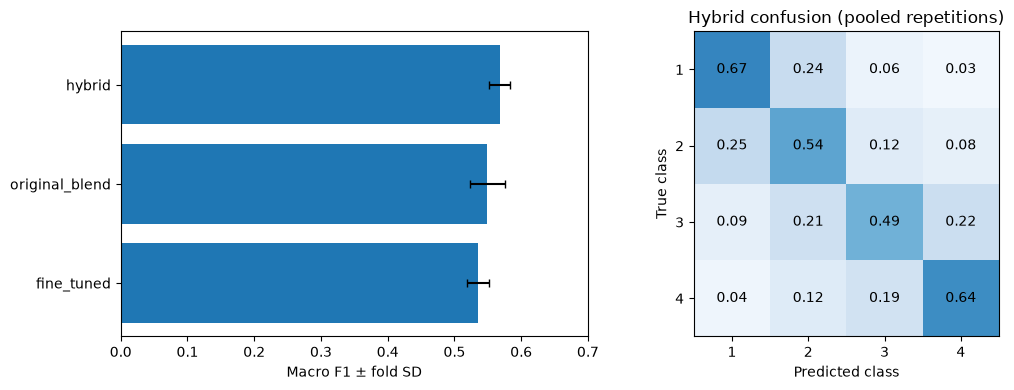

The confusion matrix pools repeated predictions; counts are not independent examples.
Fold SD is descriptive, not a confidence interval.


In [10]:
display(class_metrics.groupby(['method', 'fold', 'age_class']).f1.mean()
        .groupby(['method', 'age_class']).mean().unstack('age_class').round(4))
paired = folds.macro_f1.unstack('method')
paired['hybrid_minus_rf'] = paired.hybrid - paired.original_blend
paired.to_csv(OUT / 'paired_fold_scores.csv')
display(paired.round(5))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = summary.sort_values('macro_f1').index
axes[0].barh(order, summary.loc[order, 'macro_f1'],
             xerr=summary.loc[order, 'macro_f1_fold_sd'], capsize=3)
axes[0].set(xlabel='Macro F1 ± fold SD', xlim=(0, .7))
counts = confusion_matrix(
    predictions.loc[predictions.method.eq('hybrid'), 'y_true'],
    predictions.loc[predictions.method.eq('hybrid'), 'y_pred'], labels=CLASSES)
normalized = counts / counts.sum(axis=1, keepdims=True)
axes[1].imshow(normalized, vmin=0, vmax=1, cmap='Blues')
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f'{normalized[i,j]:.2f}', ha='center', va='center')
axes[1].set(xticks=range(4), xticklabels=CLASSES, yticks=range(4), yticklabels=CLASSES,
            xlabel='Predicted class', ylabel='True class', title='Hybrid confusion (pooled repetitions)')
fig.tight_layout()
fig.savefig(OUT / 'comparison.png', dpi=160)
plt.show()
print('The confusion matrix pools repeated predictions; counts are not independent examples.')
print('Fold SD is descriptive, not a confidence interval.')

## 9. Verify predictions and reproduce the saved experiment

Every metric below is recomputed from the exported validation probabilities. If the earlier transfer artifacts are present, their full per-location probabilities are compared against this independently trained notebook. The earlier artifacts are optional and are never needed for training.

In [11]:
persisted = pd.read_parquet(OUT / 'validation_predictions.parquet')
assert len(persisted) == len(amsterdam) * 3 * 3
saved_runs = pd.read_csv(OUT / 'run_metrics.csv').set_index(['method', 'fold', 'repetition'])
assert len(saved_runs) == 45 and saved_runs.index.is_unique
for key, frame in persisted.groupby(['method', 'fold', 'repetition']):
    assert frame.location_id.is_unique
    p = frame[[f'p{c}' for c in CLASSES]].to_numpy()
    validate_probabilities(p, len(frame))
    np.testing.assert_array_equal(frame.y_pred, CLASSES[p.argmax(1)])
    for metric, value in metrics(frame.y_true.to_numpy(), p).items():
        np.testing.assert_allclose(value, saved_runs.loc[key, metric], atol=1e-12)
previous_path = ROOT / 'data/torch_transfer/predictions.parquet'
if previous_path.exists():
    previous = pd.read_parquet(previous_path)
    previous = previous.loc[previous.method.isin(['original_blend', 'fine_tuned', 'rf_fine_tuned_blend'])].copy()
    previous['method'] = previous.method.replace({'rf_fine_tuned_blend': 'hybrid'})
    key = ['method', 'fold', 'repetition', 'location_id']
    old = previous.set_index(key).sort_index()
    new = persisted.set_index(key).sort_index()
    pd.testing.assert_index_equal(new.index, old.index)
    np.testing.assert_array_equal(new.y_true, old.y_true)
    np.testing.assert_allclose(new[[f'p{c}' for c in CLASSES]], old[[f'p{c}' for c in CLASSES]], atol=1e-6)
    print('All regenerated probabilities match the earlier transfer experiment within 1e-6.')
print('Verified all 45 saved run scores and', len(persisted), 'probability rows.')

All regenerated probabilities match the earlier transfer experiment within 1e-6.
Verified all 45 saved run scores and 233928 probability rows.


## 10. Train a separate final adaptation model

Cross-validation models exclude their evaluation fold. A final prediction bundle instead uses a specified set of **100 permitted Amsterdam labels** across the available training area.

Set `FINAL_LABEL_IDS_CSV` to a CSV with a `location_id` column containing exactly 25 authorized labels/class. If left as `None`, the notebook selects a fixed seeded development sample from the available Amsterdam training table. This default is a local demonstration, not a claim that those IDs are the organizer's authorized competition sample. It never uses all Amsterdam labels for model fitting, and no validation score is assigned to the final bundle.

The source models remain the same. Only the Amsterdam RF and neural adaptation are refitted on the selected final sample. This final bundle has not itself been independently evaluated.

In [12]:
FINAL_LABEL_IDS_CSV = None  # Example: ROOT / 'data/authorized_amsterdam_ids.csv'
FINAL_SEED = 20042
if FINAL_LABEL_IDS_CSV is None:
    rng = np.random.default_rng(FINAL_SEED)
    final_ids = []
    for cls in CLASSES:
        candidates = amsterdam.loc[amsterdam.age_class.eq(cls), 'location_id'].sort_values().to_numpy()
        final_ids.extend(rng.permutation(candidates)[:25])
    final_sample_origin = 'Seeded local development demonstration'
else:
    ids_frame = pd.read_csv(FINAL_LABEL_IDS_CSV)
    final_ids = ids_frame.location_id.tolist()
    final_sample_origin = str(FINAL_LABEL_IDS_CSV)
assert len(final_ids) == 100 and len(set(final_ids)) == 100
final_sample = amsterdam.set_index('location_id', drop=False).loc[final_ids].reset_index(drop=True)
assert final_sample.age_class.value_counts().reindex(CLASSES).eq(25).all()
final_target_rf = make_forest(FINAL_SEED)
final_target_rf.fit(final_sample[FEATURES], final_sample.age_class)
final_x = torch.tensor(neural_preprocessing.transform(final_sample[FEATURES]), dtype=torch.float32)
final_y = torch.tensor(final_sample.age_class.to_numpy(dtype=np.int64)-1)
final_neural, final_history = fine_tune(source_neural, final_x, final_y, FINAL_SEED)
final_sample[['location_id', 'age_class']].to_csv(OUT / 'final_adaptation_membership.csv', index=False)
pd.DataFrame(final_history).to_csv(OUT / 'final_adaptation_losses.csv', index=False)
print('Final models fitted on exactly 100 Amsterdam labels. No final-model score is computed.')

Final models fitted on exactly 100 Amsterdam labels. No final-model score is computed.


## 11. Export and reload the complete prediction bundle

The bundle stores ordinary scikit-learn pipelines and PyTorch state dictionaries. Reload requires the `TransferMLP` class defined above, and no project-specific Python module. Feature ordering and probability class ordering are preserved explicitly.

In [13]:
joblib.dump(dict(source_rf=source_rf, target_rf=final_target_rf,
                 neural_preprocessing=neural_preprocessing), OUT / 'final_sklearn.joblib', compress=3)
torch.save(dict(state_dict=final_neural.state_dict(), config=CONFIG, features=FEATURES,
                class_order=CLASSES.tolist()), OUT / 'final_neural.pt')
metadata = dict(features=FEATURES, class_order=CLASSES.tolist(), config=CONFIG,
    component_weights={'madrid_rf': 0.25, 'amsterdam_rf': 0.25, 'fine_tuned_mlp': 0.5},
    rf_parameters=RF_PARAMETERS, source_checkpoint=source_details,
    final_sample_origin=final_sample_origin, final_seed=FINAL_SEED,
    final_target_labels=100, final_model_independently_evaluated=False,
    independent_competition_test_available=False,
    score_scope='Spatial development CV, not a score for the final fitted bundle',
    cv_macro_f1={str(m): float(v) for m, v in summary.macro_f1.items()},
    inputs={str(p.relative_to(ROOT)): sha(p) for p in REQUIRED},
    versions=dict(python=platform.python_version(), torch=torch.__version__, sklearn=sklearn.__version__,
                  numpy=np.__version__, pandas=pd.__version__))
(OUT / 'hybrid_metadata.json').write_text(json.dumps(metadata, indent=2)+'\n')


def load_hybrid(folder):
    folder = Path(folder)
    meta = json.loads((folder / 'hybrid_metadata.json').read_text())
    if meta['features'] != FEATURES or meta['class_order'] != CLASSES.tolist():
        raise ValueError('Feature/class schema differs from this notebook.')
    if meta['config'] != CONFIG:
        raise ValueError('Model configuration differs from this notebook.')
    saved = joblib.load(folder / 'final_sklearn.joblib')
    weights = torch.load(folder / 'final_neural.pt', weights_only=True, map_location='cpu')
    assert weights['features'] == FEATURES and weights['class_order'] == CLASSES.tolist()
    model = TransferMLP(len(FEATURES))
    model.load_state_dict(weights['state_dict'])
    model.eval()
    return saved['source_rf'], saved['target_rf'], model, saved['neural_preprocessing']


loaded_hybrid = load_hybrid(OUT)
probe = amsterdam.loc[~amsterdam.location_id.isin(final_ids)].head(16)
before = hybrid_probabilities(source_rf, final_target_rf, final_neural, neural_preprocessing, probe)
after = hybrid_probabilities(*loaded_hybrid, probe)
np.testing.assert_allclose(before, after, atol=1e-7)
print('Complete final bundle saved to:', OUT)
print('Reload probabilities match the in-memory model.')

Complete final bundle saved to: /home/mirado/hack4dev/Building_Age_Classification/data/hybrid_rf_pytorch
Reload probabilities match the in-memory model.


## 12. Predict new locations and export probabilities

Set `PREDICTION_FEATURES_PATH` to a feature Parquet table with one row/location, the same observation-history preparation, the 54 predictor columns and a unique `location_id`. No labels are read for prediction. The default produces local demonstration predictions for 16 locations outside the final adaptation sample; this is not an unseen competition test.

The CSV includes the predicted class, four probabilities and maximum probability (an uncalibrated score, not a guarantee of correctness).

In [14]:
PREDICTION_FEATURES_PATH = None  # Example: ROOT / 'data/test_location_features.parquet'
if PREDICTION_FEATURES_PATH is None:
    prediction_features = probe[['location_id'] + FEATURES].copy()
    prediction_scope = 'Local feature-only demonstration; no performance score'
else:
    prediction_features = pd.read_parquet(PREDICTION_FEATURES_PATH, columns=['location_id'] + FEATURES)
    prediction_scope = str(PREDICTION_FEATURES_PATH)
assert prediction_features.location_id.is_unique
p = hybrid_probabilities(*loaded_hybrid, prediction_features)
output = pd.DataFrame(dict(location_id=prediction_features.location_id.to_numpy(),
                           predicted_age_class=CLASSES[p.argmax(1)],
                           max_probability=p.max(1),
                           **{f'p{c}': p[:, i] for i, c in enumerate(CLASSES)}))
output.to_csv(OUT / 'hybrid_predictions.csv', index=False)
print('Prediction scope:', prediction_scope)
display(output.head())
# Capture regenerated artifacts for later integrity checks.
artifact_hashes = {p.name: sha(p) for p in OUT.iterdir()
                   if p.is_file() and p.name != 'artifact_hashes.json'}
(OUT / 'artifact_hashes.json').write_text(json.dumps(artifact_hashes, indent=2)+'\n')

Prediction scope: Local feature-only demonstration; no performance score


,location_id,predicted_age_class,max_probability,p1,p2,p3,p4
0,Amsterdam:20600:193589,4,0.533418,0.031275,0.088533,0.346773,0.533418
1,Amsterdam:20600:193590,4,0.490527,0.036504,0.084196,0.388773,0.490527
2,Amsterdam:20601:193591,4,0.555111,0.018314,0.059841,0.366735,0.555111
3,Amsterdam:20601:193593,4,0.480618,0.041019,0.092655,0.385708,0.480618
4,Amsterdam:20602:193589,4,0.559764,0.021158,0.065585,0.353492,0.559764


1981

## Conclusion

The selected algorithm combines **25% Madrid RF + 25% Amsterdam RF + 50% fine-tuned MLP**. Its earlier matched development score was **0.5679 macro F1**, a **+0.0185** gain over the RF baseline. Severe errors increased, and the fine-tuned network alone did not outperform the stronger scratch control, so the hybrid gain cannot be attributed specifically to pretraining.

The table above contains this notebook's freshly recomputed scores. The exported final model uses exactly 100 Amsterdam adaptation labels and has no independent test score. Validate on an untouched geographic or competition test before claiming a generalization improvement.

Method and evaluation guidance: the installed scikit-learn skill; official [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html), [optimizer parameter groups](https://docs.pytorch.org/docs/2.15/optim.html#per-parameter-options), and [reproducibility guidance](https://docs.pytorch.org/docs/2.15/notes/randomness.html). Project details and trade-offs: [transfer report](../../docs/TORCH_TRANSFER.md).